# Optimasi Biaya Sewa Cloud Server: Program Linear

## Kelompok 2 Kelas A
2408561001, Nayla Lareina Widyastuti Seregar

2408561004, Si Ngurah Putu Juliarta

2408561025, I Wayan Yudhiastara Sudarmawan

2408061049, I Gusti Ayu Titania Pramesti Maharani

2408561114, I Putu Wahyu Eka Saputra

**Soal 2: Pemodelan dan Simulasi**

Variabel keputusan: $x$ = jam sewa Server Standar, $y$ = jam sewa Server Performa Tinggi.

$$\min Z = 8000x + 12000y$$
$$\text{s.t.}\quad 20x + 10y \ge 100 \;\;(\text{instruksi}),\qquad 10x + 30y \ge 90 \;\;(\text{akses basis data}),\qquad x, y \ge 0$$


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog

c = [8000, 12000]                 # biaya per jam
A = [[20, 10],                    # instruksi pemrosesan / jam
     [10, 30]]                    # permintaan akses basis data / jam
b = [100, 90]                     # kebutuhan minimal

## 1. Metode Grafik — Titik Pojok Daerah Layak

In [2]:
# titik potong kedua garis kendala
xp, yp = np.linalg.solve(A, b)
# titik pojok: perpotongan dengan sumbu dan perpotongan kedua garis
kandidat = [(0, b[0]/A[0][1]), (0, b[1]/A[1][1]), (b[0]/A[0][0], 0), (b[1]/A[1][0], 0), (xp, yp)]
layak = lambda x, y: all(a1*x + a2*y >= bi - 1e-9 for (a1, a2), bi in zip(A, b))

print(f"{'Titik (x, y)':<16}{'Layak':<8}{'Z (Rp)':>10}")
for x, y in kandidat:
    ok = layak(x, y)
    z = f"{c[0]*x + c[1]*y:,.0f}" if ok else '-'
    print(f"({x:.1f}, {y:.1f}){'':<6}{'ya' if ok else 'tidak':<8}{z:>10}")

Titik (x, y)    Layak       Z (Rp)
(0.0, 10.0)      ya         120,000
(0.0, 3.0)      tidak            -
(5.0, 0.0)      tidak            -
(9.0, 0.0)      ya          72,000
(4.2, 1.6)      ya          52,800


## 2. Visualisasi Daerah Layak

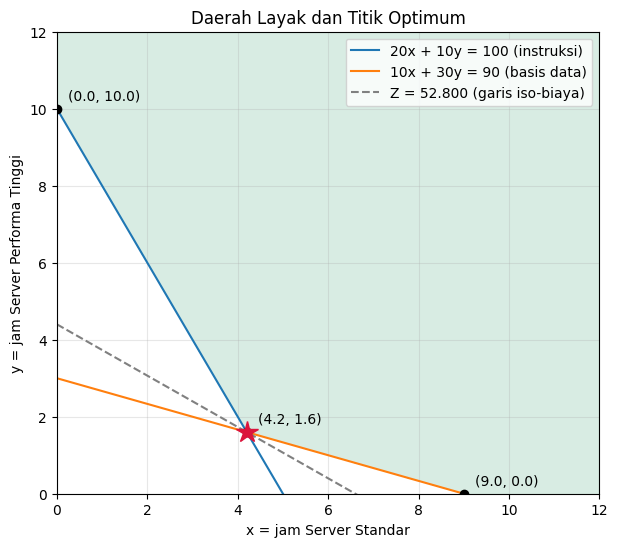

In [3]:
xs = np.linspace(0, 12, 400)
X, Y = np.meshgrid(xs, np.linspace(0, 12, 400))
area = (20*X + 10*Y >= 100) & (10*X + 30*Y >= 90)

fig, ax = plt.subplots(figsize=(7, 6))
ax.contourf(X, Y, area, levels=[0.5, 1], colors=['#cfe8dc'], alpha=0.8)
ax.plot(xs, (100 - 20*xs)/10, label='20x + 10y = 100 (instruksi)')
ax.plot(xs, (90 - 10*xs)/30, label='10x + 30y = 90 (basis data)')
ax.plot(xs, (52800 - 8000*xs)/12000, '--', color='gray', label='Z = 52.800 (garis iso-biaya)')
for x, y in [(0, 10), (xp, yp), (9, 0)]:
    ax.plot(x, y, 'o', color='black')
    ax.annotate(f'({x:.1f}, {y:.1f})', (x, y), textcoords='offset points', xytext=(8, 6))
ax.plot(xp, yp, '*', ms=16, color='crimson')
ax.set(xlim=(0, 12), ylim=(0, 12), xlabel='x = jam Server Standar', ylabel='y = jam Server Performa Tinggi',
       title='Daerah Layak dan Titik Optimum')
ax.legend(); ax.grid(alpha=0.3)
plt.savefig('grafik_daerah_layak.png', dpi=200, bbox_inches='tight'); plt.show()

## 3. Verifikasi dengan `scipy.optimize.linprog`
`linprog` hanya menerima kendala $\le$, sehingga kendala $\ge$ dikalikan $-1$.

In [4]:
res = linprog(c, A_ub=-np.array(A), b_ub=-np.array(b), bounds=[(0, None)]*2, method='highs')
x_opt, y_opt = res.x
print(f"Status        : {res.message}")
print(f"Server Standar        x = {x_opt:.2f} jam")
print(f"Server Performa Tinggi y = {y_opt:.2f} jam")
print(f"Biaya minimum         Z = Rp {res.fun:,.0f}")
print(f"Instruksi terpenuhi   : {20*x_opt + 10*y_opt:.0f} (min 100)")
print(f"Akses DB terpenuhi    : {10*x_opt + 30*y_opt:.0f} (min 90)")
print(f"Shadow price (dual)   : {-res.ineqlin.marginals}")

Status        : Optimization terminated successfully. (HiGHS Status 7: Optimal)
Server Standar        x = 4.20 jam
Server Performa Tinggi y = 1.60 jam
Biaya minimum         Z = Rp 52,800
Instruksi terpenuhi   : 100 (min 100)
Akses DB terpenuhi    : 90 (min 90)
Shadow price (dual)   : [240. 320.]


## 4. Jika Sewa Harus Dalam Jam Bulat

In [5]:
res_int = linprog(c, A_ub=-np.array(A), b_ub=-np.array(b), bounds=[(0, None)]*2,
                  integrality=[1, 1], method='highs')
print(f"x = {res_int.x[0]:.0f} jam, y = {res_int.x[1]:.0f} jam, Z = Rp {res_int.fun:,.0f}")

x = 4 jam, y = 2 jam, Z = Rp 56,000
